In [1]:
from pathlib import Path
import copy
import random

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)


PyTorch: 2.5.1
Device: cuda


In [2]:
DATA_DIR = Path(r'D:\IMD\Lucknow\lucknow_worked\07_LSTM_READY_DATA')
DATA_FILE = DATA_DIR / 'lucknow_unified_lstm_dataset_aug2024_dec2025.csv'
SUMMARY_FILE = DATA_DIR / 'lucknow_unified_lstm_dataset_summary.csv'
RESULTS_DIR = Path(r'D:\\IMD\\Lucknow\\result\\train_lucknow_lstm_range_aware')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR = RESULTS_DIR
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COLUMNS = ['CLOUD_Vertical_Visibility', 'VIS_Visibility_MOR']
TIMESTAMP_COLUMN = 'Datetime'
LOOKBACK = 96
HORIZON = 1
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
BATCH_SIZE = 256
EPOCHS = 60
PATIENCE = 10
LOW_THRESHOLD = 1000.0
MEDIUM_THRESHOLD = 5000.0
REGIME_WEIGHTS = {'low': 4.0, 'medium': 2.5, 'high': 1.0}

assert DATA_FILE.exists()
assert SUMMARY_FILE.exists()


In [3]:
summary = pd.read_csv(SUMMARY_FILE)
display(summary)
df = pd.read_csv(DATA_FILE, low_memory=False)
df[TIMESTAMP_COLUMN] = pd.to_datetime(df[TIMESTAMP_COLUMN], errors='coerce')
df = (df.dropna(subset=[TIMESTAMP_COLUMN] + TARGET_COLUMNS)
        .drop_duplicates(subset=[TIMESTAMP_COLUMN])
        .sort_values(TIMESTAMP_COLUMN)
        .reset_index(drop=True))
assert df[TIMESTAMP_COLUMN].is_monotonic_increasing
assert not df[TIMESTAMP_COLUMN].duplicated().any()
print('Rows:', len(df))
print('Date range:', df[TIMESTAMP_COLUMN].min(), 'to', df[TIMESTAMP_COLUMN].max())


,Input_Directory,Output_File,Start_Date_Inclusive,End_Date_Exclusive,Files_Discovered,Files_Processed,Files_Failed,Rows_Read,Rows_In_Date_Range,Invalid_Datetime_Rows,Duplicate_Timestamp_Rows_Removed,Rows_Written,Columns_Written,Column_Names
0,D:\IMD\Lucknow\lucknow_worked\07_LSTM_READY_DATA,D:\IMD\Lucknow\lucknow_worked\07_LSTM_READY_DA...,2024-08-01,2026-01-01,541,541,0,2765299,2520761,0,0,2520761,23,"Datetime, CLOUD_Cloud_Base_1, CLOUD_Cloud_Base..."


Rows: 2520761
Date range: 2024-08-08 00:00:00 to 2025-12-31 23:59:45


In [4]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
feature_columns = numeric_columns.copy()
n_rows = len(df)
train_end = int(n_rows * TRAIN_RATIO)
validation_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))
train_frame = df.iloc[:train_end].copy()
validation_frame = df.iloc[train_end:validation_end].copy()
test_frame = df.iloc[validation_end:].copy()

for frame in (train_frame, validation_frame, test_frame):
    frame[feature_columns] = frame[feature_columns].replace([np.inf, -np.inf], np.nan)
    
feature_columns = [c for c in feature_columns if train_frame[c].notna().any()]
train_medians = train_frame[feature_columns].median().fillna(0.0)
for frame in (train_frame, validation_frame, test_frame):
    frame[feature_columns] = frame[feature_columns].fillna(train_medians)

feature_scaler = StandardScaler().fit(train_frame[feature_columns])
train_features = feature_scaler.transform(train_frame[feature_columns]).astype(np.float32)
validation_features = feature_scaler.transform(validation_frame[feature_columns]).astype(np.float32)
test_features = feature_scaler.transform(test_frame[feature_columns]).astype(np.float32)
train_targets_raw = train_frame[TARGET_COLUMNS].to_numpy(np.float32)
validation_targets_raw = validation_frame[TARGET_COLUMNS].to_numpy(np.float32)
test_targets_raw = test_frame[TARGET_COLUMNS].to_numpy(np.float32)
print('Features:', len(feature_columns))
print('Dropped all-null features:', sorted(set(numeric_columns) - set(feature_columns)))


Features: 21
Dropped all-null features: ['CLOUD_SITE']


In [7]:
class ResidualSequenceDataset(torch.utils.data.Dataset):
    def __init__(self, features, residual_targets, lookback, horizon):
        self.features = features
        self.residual_targets = residual_targets
        self.lookback = lookback
        self.horizon = horizon
        self.count = len(residual_targets)
        expected_count = len(features) - lookback - horizon + 1
        if self.count != expected_count:
            raise ValueError(
                f'Feature/target length mismatch: expected {expected_count}, got {self.count}'
            )

    def __len__(self):
        return self.count

    def __getitem__(self, index):
        end = index + self.lookback
        return (
            torch.from_numpy(self.features[index:end].copy()),
            torch.from_numpy(self.residual_targets[index].copy()),
        )


def aligned_targets(targets_raw, lookback, horizon):
    count = len(targets_raw) - lookback - horizon + 1
    if count <= 0:
        raise ValueError('The split is shorter than LOOKBACK + HORIZON.')
    persistence = targets_raw[lookback - 1:lookback - 1 + count]
    future = targets_raw[lookback + horizon - 1:lookback + horizon - 1 + count]
    return future.astype(np.float32), persistence.astype(np.float32)

train_future, train_persistence = aligned_targets(train_targets_raw, LOOKBACK, HORIZON)
validation_future, validation_persistence = aligned_targets(validation_targets_raw, LOOKBACK, HORIZON)
test_future, test_persistence = aligned_targets(test_targets_raw, LOOKBACK, HORIZON)

train_residual = np.log1p(np.maximum(train_future, 0)) - np.log1p(np.maximum(train_persistence, 0))
validation_residual = np.log1p(np.maximum(validation_future, 0)) - np.log1p(np.maximum(validation_persistence, 0))
test_residual = np.log1p(np.maximum(test_future, 0)) - np.log1p(np.maximum(test_persistence, 0))
residual_scaler = StandardScaler().fit(train_residual)
y_train = residual_scaler.transform(train_residual).astype(np.float32)
y_validation = residual_scaler.transform(validation_residual).astype(np.float32)
y_test = residual_scaler.transform(test_residual).astype(np.float32)

train_dataset = ResidualSequenceDataset(train_features, y_train, LOOKBACK, HORIZON)
validation_dataset = ResidualSequenceDataset(validation_features, y_validation, LOOKBACK, HORIZON)
test_dataset = ResidualSequenceDataset(test_features, y_test, LOOKBACK, HORIZON)

assert len(train_dataset) == len(train_future) == len(train_persistence)
assert len(validation_dataset) == len(validation_future) == len(validation_persistence)
assert len(test_dataset) == len(test_future) == len(test_persistence)
assert np.isfinite(train_features).all() and np.isfinite(y_train).all()
print('Lazy sequence counts:', len(train_dataset), len(validation_dataset), len(test_dataset))
print('Aligned array lengths:', len(train_future), len(train_persistence), len(validation_future), len(validation_persistence), len(test_future), len(test_persistence))
print('No full overlapping window arrays are allocated.')


Lazy sequence counts: 1764436 378018 378019
Aligned array lengths: 1764436 1764436 378018 378018 378019 378019
No full overlapping window arrays are allocated.


In [8]:
def regime_weight(values):
    weights = np.where(values < LOW_THRESHOLD, REGIME_WEIGHTS['low'],
                       np.where(values < MEDIUM_THRESHOLD, REGIME_WEIGHTS['medium'], REGIME_WEIGHTS['high']))
    return weights.astype(np.float32)

sample_weights = (regime_weight(train_future[:, 0]) + regime_weight(train_future[:, 1])) / 2.0
sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True,
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)


In [9]:
class RangeAwareLSTM(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, 128, num_layers=2, batch_first=True, dropout=0.2)
        self.norm = nn.LayerNorm(128)
        self.head = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, output_size))

    def forward(self, inputs):
        outputs, _ = self.lstm(inputs)
        return self.head(self.norm(outputs[:, -1, :]))

model = RangeAwareLSTM(len(feature_columns), len(TARGET_COLUMNS)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4, min_lr=1e-6)
criterion = nn.SmoothL1Loss(reduction='none', beta=0.5)
print(model)


RangeAwareLSTM(
  (lstm): LSTM(21, 128, num_layers=2, batch_first=True, dropout=0.2)
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [11]:
def run_epoch(loader, training):
    model.train(training)
    total_loss, total_items = 0.0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            predictions = model(inputs)
            point_loss = criterion(predictions, targets)
            loss = point_loss.mean()
            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(inputs)
            total_items += len(inputs)
    return total_loss / total_items

history = {'loss': [], 'val_loss': []}
best_loss, best_state, stale = float('inf'), None, 0
for epoch in range(EPOCHS):
    train_loss = run_epoch(train_loader, True)
    validation_loss = run_epoch(validation_loader, False)
    scheduler.step(validation_loss)
    history['loss'].append(train_loss)
    history['val_loss'].append(validation_loss)+32
    print(f'Epoch {epoch + 1:03d}/{EPOCHS} - loss: {train_loss:.6f} - val_loss: {validation_loss:.6f}')
    if validation_loss < best_loss:
        best_loss, stale = validation_loss, 0
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, ARTIFACT_DIR / 'best_range_aware_lstm.pt')
    else:
        stale += 1
        if stale >= PATIENCE:
            print('Early stopping.')
            break
model.load_state_dict(best_state)


Epoch 001/60 - loss: 0.102572 - val_loss: 0.078832
Epoch 002/60 - loss: 0.100849 - val_loss: 0.078422
Epoch 003/60 - loss: 0.101402 - val_loss: 0.078171
Epoch 004/60 - loss: 0.098823 - val_loss: 0.078139
Epoch 005/60 - loss: 0.099533 - val_loss: 0.078062
Epoch 006/60 - loss: 0.099371 - val_loss: 0.078022
Epoch 007/60 - loss: 0.098889 - val_loss: 0.077877
Epoch 008/60 - loss: 0.099295 - val_loss: 0.078011
Epoch 009/60 - loss: 0.097677 - val_loss: 0.078090
Epoch 010/60 - loss: 0.096667 - val_loss: 0.077885
Epoch 011/60 - loss: 0.098375 - val_loss: 0.077964
Epoch 012/60 - loss: 0.097284 - val_loss: 0.078026
Epoch 013/60 - loss: 0.096634 - val_loss: 0.077776
Epoch 014/60 - loss: 0.097253 - val_loss: 0.077679
Epoch 015/60 - loss: 0.095956 - val_loss: 0.077699
Epoch 016/60 - loss: 0.096975 - val_loss: 0.077682
Epoch 017/60 - loss: 0.096108 - val_loss: 0.077691
Epoch 018/60 - loss: 0.096584 - val_loss: 0.077754
Epoch 019/60 - loss: 0.095057 - val_loss: 0.077725
Epoch 020/60 - loss: 0.096203 -

<All keys matched successfully>

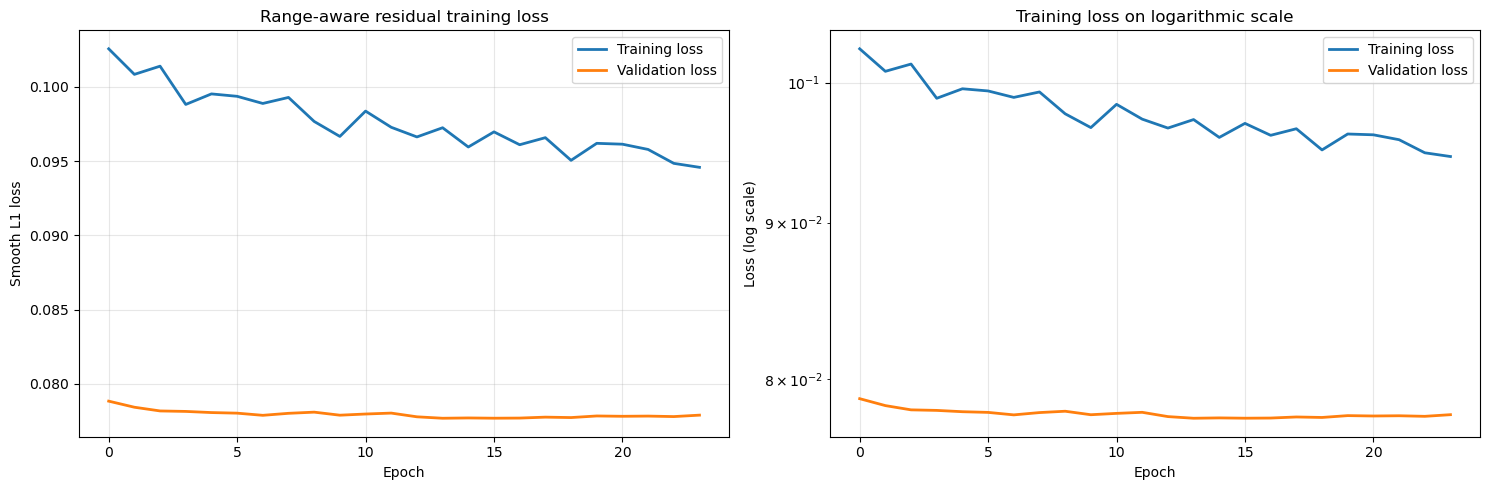

In [16]:
history_frame = pd.DataFrame(history)
history_frame.to_csv(ARTIFACT_DIR / 'range_aware_training_history.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history_frame['loss'], label='Training loss', linewidth=2)
axes[0].plot(history_frame['val_loss'], label='Validation loss', linewidth=2)
axes[0].set_title('Range-aware residual training loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Smooth L1 loss')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(history_frame['loss'], label='Training loss', linewidth=2)
axes[1].plot(history_frame['val_loss'], label='Validation loss', linewidth=2)
axes[1].set_yscale('log')
axes[1].set_title('Training loss on logarithmic scale')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss (log scale)')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


In [12]:
def predict_residual_dataset(dataset):
    model.eval()
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    outputs = []
    with torch.no_grad():
        for inputs, _ in loader:
            outputs.append(model(inputs.to(DEVICE)).cpu().numpy())
    return residual_scaler.inverse_transform(np.concatenate(outputs))

def predict_raw(dataset, persistence):
    residual = predict_residual_dataset(dataset)
    prediction_log = np.log1p(np.maximum(persistence, 0)) + residual
    return np.maximum(np.expm1(prediction_log), 0)

validation_predictions = predict_raw(validation_dataset, validation_persistence)
test_predictions = predict_raw(test_dataset, test_persistence)

# Tune a convex model/persistence blend on validation only.
alphas = np.linspace(0.0, 1.0, 21)
blend_alphas = []
for index in range(len(TARGET_COLUMNS)):
    scores = [mean_absolute_error(validation_future[:, index], alpha * validation_predictions[:, index] + (1 - alpha) * validation_persistence[:, index]) for alpha in alphas]
    blend_alphas.append(float(alphas[int(np.argmin(scores))]))
blend_predictions = np.column_stack([
    alpha * test_predictions[:, index] + (1 - alpha) * test_persistence[:, index]
    for index, alpha in enumerate(blend_alphas)
])
print('Validation-tuned model weights:', dict(zip(TARGET_COLUMNS, blend_alphas)))


Validation-tuned model weights: {'CLOUD_Vertical_Visibility': 0.0, 'VIS_Visibility_MOR': 0.0}


In [13]:
def metrics_table(actual, predicted, label):
    rows = []
    for index, target in enumerate(TARGET_COLUMNS):
        rows.append({'method': label, 'target': target,
                     'MAE': mean_absolute_error(actual[:, index], predicted[:, index]),
                     'RMSE': mean_squared_error(actual[:, index], predicted[:, index]) ** 0.5,
                     'R2': r2_score(actual[:, index], predicted[:, index])})
    return pd.DataFrame(rows)

global_metrics = pd.concat([
    metrics_table(test_future, test_predictions, 'range_aware_lstm'),
    metrics_table(test_future, test_persistence, 'persistence'),
    metrics_table(test_future, blend_predictions, 'validation_tuned_blend'),
], ignore_index=True)
display(global_metrics)
global_metrics.to_csv(ARTIFACT_DIR / 'range_aware_global_metrics.csv', index=False)


,method,target,MAE,RMSE,R2
0,range_aware_lstm,CLOUD_Vertical_Visibility,13.706547,404.092618,0.984787
1,range_aware_lstm,VIS_Visibility_MOR,36.810585,166.510152,0.997765
2,persistence,CLOUD_Vertical_Visibility,12.940503,404.065395,0.984789
3,persistence,VIS_Visibility_MOR,35.316612,173.304555,0.997579
4,validation_tuned_blend,CLOUD_Vertical_Visibility,12.940503,404.065395,0.984789
5,validation_tuned_blend,VIS_Visibility_MOR,35.316612,173.304555,0.997579


In [14]:
def range_metrics(actual, predicted, method):
    rows = []
    for target_index, target in enumerate(TARGET_COLUMNS):
        values = actual[:, target_index]
        for name, mask in [('low', values < LOW_THRESHOLD), ('medium', (values >= LOW_THRESHOLD) & (values < MEDIUM_THRESHOLD)), ('high', values >= MEDIUM_THRESHOLD)]:
            if mask.sum() == 0:
                continue
            rows.append({'method': method, 'target': target, 'range': name, 'samples': int(mask.sum()),
                         'MAE': mean_absolute_error(values[mask], predicted[mask, target_index]),
                         'RMSE': mean_squared_error(values[mask], predicted[mask, target_index]) ** 0.5,
                         'R2': r2_score(values[mask], predicted[mask, target_index]) if mask.sum() > 1 else np.nan})
    return pd.DataFrame(rows)

range_results = pd.concat([
    range_metrics(test_future, test_predictions, 'range_aware_lstm'),
    range_metrics(test_future, test_persistence, 'persistence'),
    range_metrics(test_future, blend_predictions, 'validation_tuned_blend'),
], ignore_index=True)
display(range_results)
range_results.to_csv(ARTIFACT_DIR / 'range_aware_range_metrics.csv', index=False)


,method,target,range,samples,MAE,RMSE,R2
0,range_aware_lstm,CLOUD_Vertical_Visibility,low,12556,89.627625,1144.196552,-203.724197
1,range_aware_lstm,CLOUD_Vertical_Visibility,medium,12176,109.465302,1063.157444,-2.758535
2,range_aware_lstm,CLOUD_Vertical_Visibility,high,353287,7.707960,298.725836,-1.210124
3,range_aware_lstm,VIS_Visibility_MOR,low,72281,5.954677,26.558155,0.991861
4,range_aware_lstm,VIS_Visibility_MOR,medium,160722,18.902941,59.707026,0.997128
5,range_aware_lstm,VIS_Visibility_MOR,high,145016,72.037376,260.712291,0.982224
6,persistence,CLOUD_Vertical_Visibility,low,12556,89.605125,1143.958588,-203.639053
7,persistence,CLOUD_Vertical_Visibility,medium,12176,109.442017,1063.108532,-2.758189
8,persistence,CLOUD_Vertical_Visibility,high,353287,6.889888,298.724868,-1.210110
9,persistence,VIS_Visibility_MOR,low,72281,5.578229,28.300213,0.990758


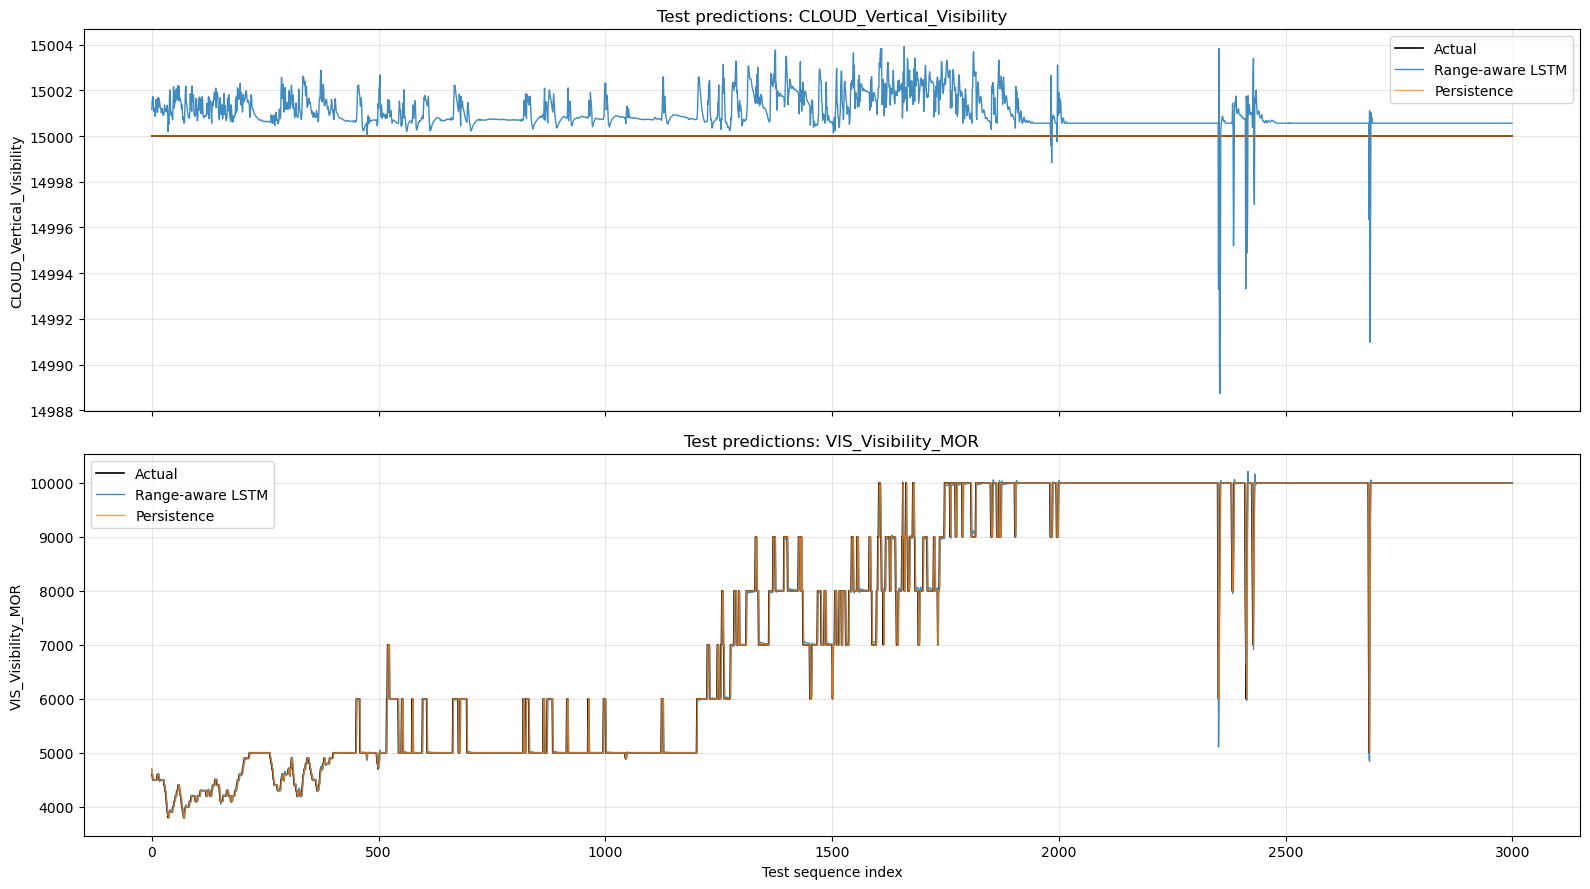

In [17]:
# Plot a representative chronological section of test predictions.
plot_count = min(3000, len(test_future))
plot_slice = slice(0, plot_count)

fig, axes = plt.subplots(len(TARGET_COLUMNS), 1, figsize=(16, 9), sharex=True)
axes = np.atleast_1d(axes)
for index, target in enumerate(TARGET_COLUMNS):
    axes[index].plot(test_future[plot_slice, index], label='Actual', linewidth=1.2, color='black')
    axes[index].plot(test_predictions[plot_slice, index], label='Range-aware LSTM', linewidth=1.0, alpha=0.85)
    axes[index].plot(test_persistence[plot_slice, index], label='Persistence', linewidth=1.0, alpha=0.75)
    axes[index].set_title(f'Test predictions: {target}')
    axes[index].set_ylabel(target)
    axes[index].grid(alpha=0.3)
    axes[index].legend()
axes[-1].set_xlabel('Test sequence index')
plt.tight_layout()
plt.show()


In [15]:
torch.save(model.state_dict(), ARTIFACT_DIR / 'range_aware_lstm_final.pt')
joblib.dump(feature_scaler, ARTIFACT_DIR / 'range_aware_feature_scaler.joblib')
joblib.dump(residual_scaler, ARTIFACT_DIR / 'range_aware_residual_scaler.joblib')
joblib.dump({'feature_columns': feature_columns, 'target_columns': TARGET_COLUMNS, 'lookback': LOOKBACK, 'horizon': HORIZON, 'blend_alphas': blend_alphas, 'low_threshold': LOW_THRESHOLD, 'medium_threshold': MEDIUM_THRESHOLD}, ARTIFACT_DIR / 'range_aware_training_config.joblib')
print('Saved artifacts to:', ARTIFACT_DIR)


Saved artifacts to: D:\IMD\Lucknow\result\train_lucknow_lstm_range_aware


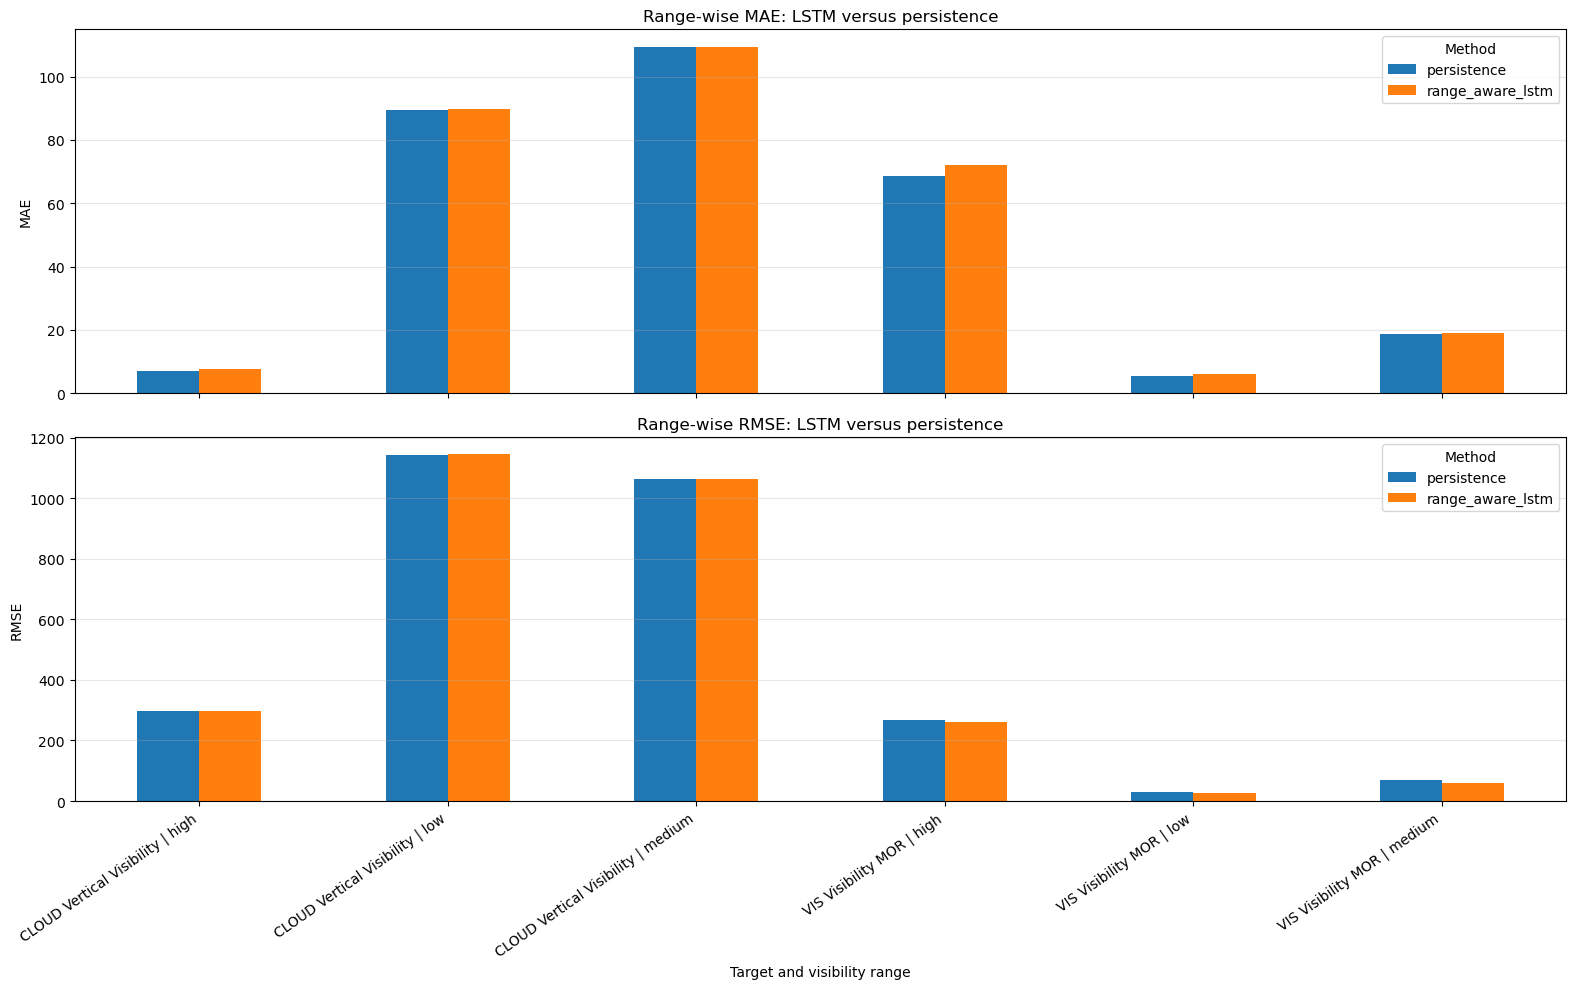

In [18]:
# Compare range-wise MAE and RMSE for the LSTM and persistence baseline.
plot_metrics = range_results[range_results['method'].isin(['range_aware_lstm', 'persistence'])].copy()
plot_metrics['label'] = plot_metrics['target'].str.replace('_', ' ', regex=False)
plot_metrics['target_range'] = plot_metrics['label'] + ' | ' + plot_metrics['range']

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)
plot_metrics.pivot(index='target_range', columns='method', values='MAE').plot(kind='bar', ax=axes[0])
axes[0].set_title('Range-wise MAE: LSTM versus persistence')
axes[0].set_ylabel('MAE')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend(title='Method')

plot_metrics.pivot(index='target_range', columns='method', values='RMSE').plot(kind='bar', ax=axes[1])
axes[1].set_title('Range-wise RMSE: LSTM versus persistence')
axes[1].set_ylabel('RMSE')
axes[1].set_xlabel('Target and visibility range')
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend(title='Method')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()
